# Decoding saccades from LIP: resolution vs. sensitivity

In the last notebook, we analyzed functional ultrasound data from a human motor cortex and recovered task-related activity with a GLM. Here, we'll go one step further and ask whether we can read out *what* an animal is planning to do on a single trial, and what it is about functional ultrasound that makes that possible.

We'll re-analyze data from [Griggs et al. (2025), *Functional ultrasound neuroimaging reveals mesoscopic organization of saccades in the lateral intraparietal area*](https://www.ncbi.nlm.nih.gov/pmc/articles/PMC12488887/). Two macaques performed memory-guided saccades while the authors imaged the left posterior parietal cortex. The lateral intraparietal area (LIP) is a classic node for planning eye movements: neurons there fire during the delay between a flashed cue and the eye movement towards its remembered location. The paper finds that LIP is organized in small patches tuned to different saccade directions, and argues that fMRI lacks the resolution and sensitivity to resolve this organization.

That raises a question we can test directly with the data: if we degrade functional ultrasound to look more like fMRI, what hurts decoding more—**coarser voxels** or **lower sensitivity**? fMRI differs from fUS in both:

* **Resolution**: fUS voxels are ~100 μm × 100 μm in plane (× 400 μm thick); fMRI voxels are typically 1.5-3 mm on each side.
* **Sensitivity**: the paper reports cerebral blood volume (CBV) changes of ~10-30% with fUS, compared to BOLD changes of ~0.4-2% for similar saccade tasks with fMRI.

We'll first get to know the data, then build a single-trial decoder from scratch, and finally degrade the data along each axis separately.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import hsv_to_rgb
from scipy import stats
from scipy.ndimage import convolve

import lip_data

# Getting one session out of a 56 GB archive

The [dataset](https://data.caltech.edu/records/p5jan-02r60) is distributed as a single 56 GB zip file. Rather than downloading all of it, we can exploit the structure of zip files: they end with a table of contents (the *central directory*) listing where each file starts inside the archive. HTTP lets us request arbitrary byte ranges of a file, so we fetch the last few kB of the archive, read the table of contents, and then download only the bytes of the session we want. The details live in `lip_data.py`; it downloads in chunks so that a dropped connection resumes where it left off, and checks the result against the checksum stored in the archive.

First, let's see what's in there.

In [2]:
data_dir = "../data/lip"
sessions = lip_data.session_table(data_dir)

for monkey in ["L", "P"]:
    rows = [s for s in sessions if s["Monkey"] == monkey and s["Project"] == "8-DIR"]
    print(
        f"Monkey {monkey}: {len(rows)} sessions, {sum(s['nTrials'] for s in rows)} trials, "
        f"imaging planes {sorted({s['Slot'] for s in rows})}"
    )

Monkey L: 20 sessions, 9708 trials, imaging planes ['cor_10', 'cor_11', 'cor_12', 'cor_8', 'cor_9']
Monkey P: 18 sessions, 8174 trials, imaging planes ['cor_10', 'cor_11', 'cor_12', 'cor_5', 'cor_6', 'cor_7', 'cor_8', 'cor_9']


Each session images one coronal plane while the monkey performs a few hundred trials. We'll work with session 99 from monkey P (~300 MB).

In [3]:
path = lip_data.fetch_session(99, 1, data_dir)
S = lip_data.load_session(path)

n_trials, n_frames, nz, nx = S.doppler.shape
print(f"{n_trials} trials x {n_frames} frames x {nz} x {nx} pixels")
print(f"Pixel size: {S.dx_mm:.3f} mm (lateral) x {S.dz_mm:.3f} mm (axial), {S.frame_rate:.0f} frame/s")

286 trials x 18 frames x 128 x 128 pixels
Pixel size: 0.100 mm (lateral) x 0.099 mm (axial), 1 frame/s


Each trial is a short Power Doppler movie at 1 frame per second, aligned to the start of the trial. Each frame was formed exactly like in notebook 3: plane waves at 5 angles were compounded at 500 Hz, 250 compound images (0.5 s) were clutter-filtered with the SVD, and their power was computed pixel by pixel. The probe has 128 elements with a 100 μm pitch, and the axial pixel size is one wavelength at 15.6 MHz (~0.1 mm).

Here's the average image, the angiogram:

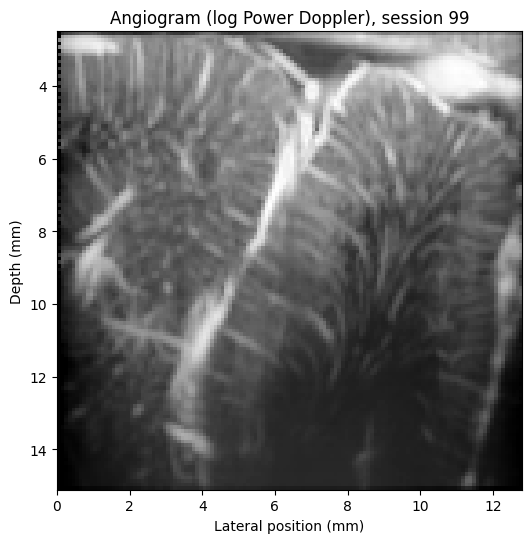

In [4]:
D = S.doppler.astype(np.float64)

# Motion correction pads the borders of the image with zeros; we'll ignore those pixels
valid = D.min(axis=(0, 1)) > 0
valid[:2, :] = valid[-2:, :] = valid[:, :2] = valid[:, -2:] = False

plt.figure(figsize=(6, 6))
plt.imshow(np.log(S.angiogram), cmap="gray", extent=S.extent)
plt.xlabel("Lateral position (mm)")
plt.ylabel("Depth (mm)")
plt.title("Angiogram (log Power Doppler), session 99")
plt.show()

The brain surface is at the top. The bright diagonal band is a large vessel running along the intraparietal sulcus; LIP lines the banks of that sulcus.

## A note on units

Power Doppler is a measure of blood volume, so we'll express responses as a percent change from baseline. That only makes sense if the stored values are proportional to the blood signal. A quick check: for a signal of the form $x = \text{CBV} \cdot (1 + \epsilon)$ with fluctuations $\epsilon$, each pixel's standard deviation should be proportional to its mean.

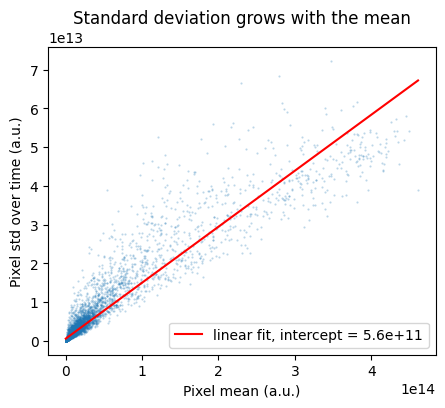

In [5]:
pixel_mean = D.mean(axis=(0, 1))[valid]
pixel_std = D.std(axis=(0, 1))[valid]
slope, intercept = np.polyfit(pixel_mean, pixel_std, 1)

plt.figure(figsize=(5, 4))
plt.plot(pixel_mean, pixel_std, ".", markersize=1, alpha=0.3)
xs = np.linspace(0, pixel_mean.max(), 10)
plt.plot(xs, slope * xs + intercept, "r-", label=f"linear fit, intercept = {intercept:.2g}")
plt.xlabel("Pixel mean (a.u.)")
plt.ylabel("Pixel std over time (a.u.)")
plt.legend()
plt.title("Standard deviation grows with the mean")
plt.show()

The relationship goes roughly through the origin, so percent changes are meaningful here. This is worth checking whenever you pick up a new dataset: in some sessions of this dataset (e.g. session 39), every pixel carries a large constant offset, which makes percent changes look ~100 times smaller than they really are unless you subtract it first.

# Trial structure

On each trial, the monkey fixates a central point, a peripheral target is flashed at one of 8 locations (the *cue*), and the monkey has to keep fixating while remembering that location (the *memory* period). When the fixation point disappears, it makes a saccade to the remembered location (*target acquire*) and gets a reward.

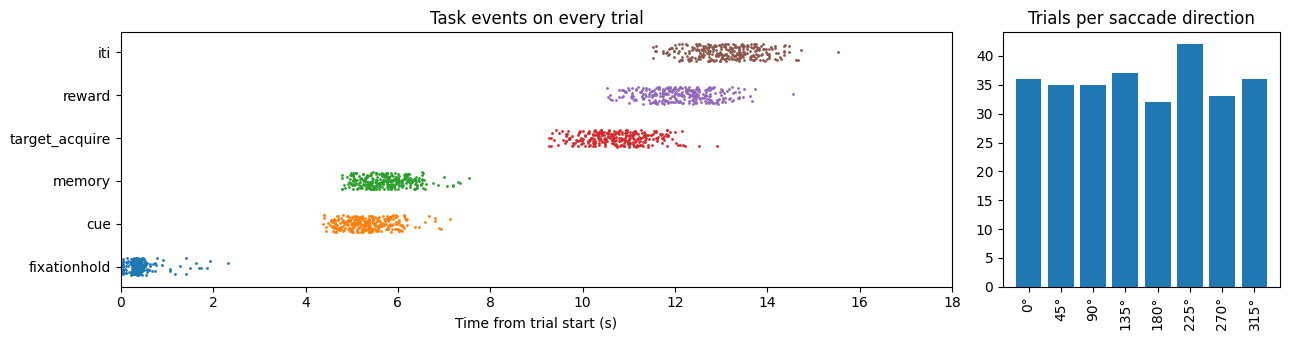

cue: median 5.3 s after trial start
target_acquire: median 10.7 s after trial start


In [6]:
events = ["fixationhold", "cue", "memory", "target_acquire", "reward", "iti"]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 3.5), gridspec_kw={"width_ratios": [3, 1]})
for i, ev in enumerate(events):
    ax1.plot(S.events[ev], np.full(n_trials, i) + np.random.uniform(-0.2, 0.2, n_trials), ".", markersize=2)
ax1.set_yticks(range(len(events)))
ax1.set_yticklabels(events)
ax1.set_xlabel("Time from trial start (s)")
ax1.set_xlim(0, n_frames)
ax1.set_title("Task events on every trial")

directions, counts = np.unique(S.target_deg, return_counts=True)
ax2.bar([f"{d:.0f}°" for d in directions], counts)
ax2.set_title("Trials per saccade direction")
ax2.tick_params(axis="x", rotation=90)
plt.tight_layout()
plt.show()

for ev in ["cue", "target_acquire"]:
    print(f"{ev}: median {np.median(S.events[ev]):.1f} s after trial start")

The cue comes ~5 s after the trial starts and the saccade ~5 s later. Directions are given as angles on the screen: 0° is rightward, 90° is upward. Since the recordings are from the *left* hemisphere, rightward saccades are *contralateral*.

# Event-locked responses

We'll measure responses as a percent change relative to the frames before the cue. The earliest cue happens at 4.4 s, so frames 0-3 (0-4 s) form a clean baseline.

In [7]:
baseline = slice(0, 4)  # frames before the earliest cue

base = D[:, baseline].mean(axis=1, keepdims=True)  # per-trial baseline
with np.errstate(divide="ignore", invalid="ignore"):
    pct = (D - base) / D[:, baseline].mean(axis=(0, 1)) * 100  # % of the pixel's average baseline
pct[:, :, ~valid] = np.nan

Which pixels respond to the task at all? Let's average the responses over a window from 8 to 13 s—a few seconds after the cue, to account for the sluggish hemodynamic response—and compute a one-sample t-statistic over trials.

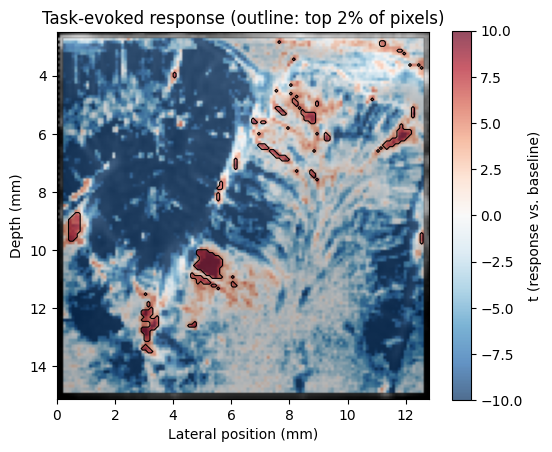

In [8]:
window = slice(8, 13)  # frames 8-12: from ~3 s after the cue to ~2 s after the saccade

response = pct[:, window].mean(axis=1)  # (trials, nz, nx)
t_task, _ = stats.ttest_1samp(response, 0, axis=0)

roi = valid & (t_task > np.nanpercentile(t_task, 98))  # top 2% most responsive pixels

plt.figure(figsize=(6, 6))
plt.imshow(np.log(S.angiogram), cmap="gray", extent=S.extent)
plt.imshow(t_task, cmap="RdBu_r", vmin=-10, vmax=10, alpha=0.7, extent=S.extent)
plt.colorbar(label="t (response vs. baseline)", shrink=0.8)
plt.contour(roi.astype(float), levels=[0.5], colors="k", linewidths=0.8, extent=S.extent, origin="upper")
plt.xlabel("Lateral position (mm)")
plt.ylabel("Depth (mm)")
plt.title("Task-evoked response (outline: top 2% of pixels)")
plt.show()

Only scattered spots increase their blood volume during the task window; much of the tissue actually *decreases* relative to the pre-cue baseline. Blood is being redistributed rather than uniformly added. Let's focus on the most strongly increasing pixels (outlined).

What does the response look like over time in these pixels? Let's compare it with the canonical hemodynamic response function (HRF) we used in notebook 4. If neurons are active from the cue to the saccade, the predicted response is that period convolved with the HRF.

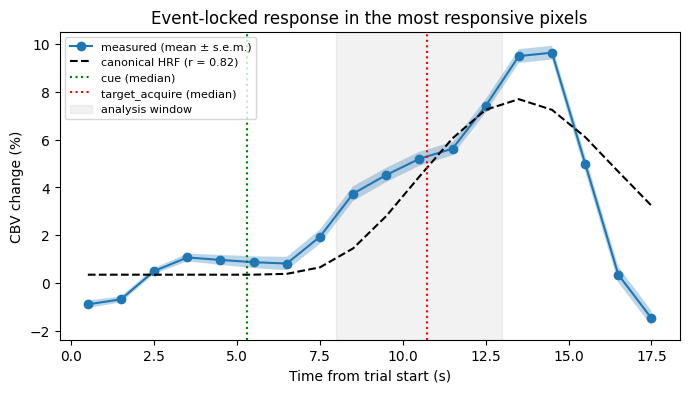

In [9]:
def canonical_hrf(t, peak_delay=6.0, undershoot_delay=16.0, peak_to_undershoot=6.0):
    """SPM-style double-gamma HRF (as in notebook 4), normalized to unit area."""
    h = stats.gamma.pdf(t, peak_delay) - stats.gamma.pdf(t, undershoot_delay) / peak_to_undershoot
    return h / h.sum()


# Predicted response for each trial: neural activity from cue to saccade, convolved with the HRF
t_fine = np.arange(0, n_frames, 0.1)
frame_centers = np.arange(n_frames) + 0.5
hrf = canonical_hrf(np.arange(0, 30, 0.1))
predicted = []
for cue, saccade in zip(S.events["cue"], S.events["target_acquire"]):
    neural = ((t_fine >= cue) & (t_fine < saccade)).astype(float)
    predicted.append(np.interp(frame_centers, t_fine, np.convolve(neural, hrf)[: len(t_fine)]))
predicted = np.mean(predicted, axis=0)

roi_tc = pct[:, :, roi].mean(axis=2)  # (trials, frames)
mean_tc = roi_tc.mean(axis=0)
sem_tc = roi_tc.std(axis=0) / np.sqrt(n_trials)
gain, offset = np.linalg.lstsq(np.vstack([predicted, np.ones(n_frames)]).T, mean_tc, rcond=None)[0]

plt.figure(figsize=(8, 4))
plt.fill_between(frame_centers, mean_tc - sem_tc, mean_tc + sem_tc, alpha=0.3)
plt.plot(frame_centers, mean_tc, "o-", label="measured (mean ± s.e.m.)")
plt.plot(frame_centers, gain * predicted + offset, "k--", label=f"canonical HRF (r = {np.corrcoef(predicted, mean_tc)[0, 1]:.2f})")
for ev, color in [("cue", "g"), ("target_acquire", "r")]:
    plt.axvline(np.median(S.events[ev]), color=color, linestyle=":", label=f"{ev} (median)")
plt.axvspan(window.start, window.stop, color="gray", alpha=0.1, label="analysis window")
plt.xlabel("Time from trial start (s)")
plt.ylabel("CBV change (%)")
plt.title("Event-locked response in the most responsive pixels")
plt.legend(fontsize=8)
plt.show()

Blood volume starts rising a few seconds after the cue, keeps growing through the memory period and the saccade, and peaks at ~10% about 4 s after the saccade. The canonical HRF captures the overall rise, but not the details: the measured response peaks a little later and comes back down much faster. That's not too surprising—the canonical HRF was derived from BOLD fMRI, CBV responses have their own dynamics, and the reward and the end of the trial drive activity too.

Note the size of the response: ~10% is an order of magnitude larger than typical BOLD signal changes. Remember this, it will matter later.

# Direction tuning maps

The response above is averaged over all 8 directions. Do different pixels prefer different directions? The paper smooths the images slightly before mapping tuning (a 1-pixel-radius disk), and so will we. Let's start with the simplest contrast: contralateral (rightward) vs. ipsilateral (leftward) saccades.

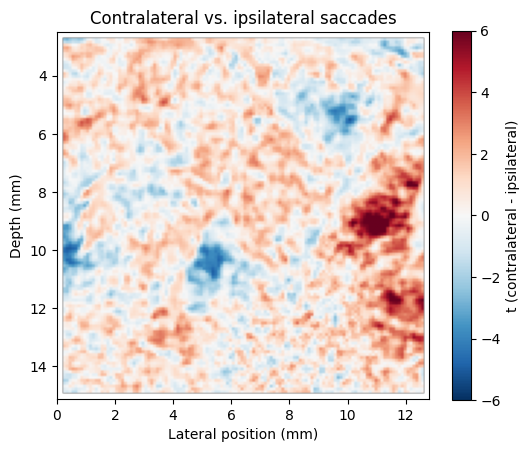

In [10]:
disk = np.array([[0, 1, 0], [1, 1, 1], [0, 1, 0]], dtype=float)
disk /= disk.sum()
response_smooth = convolve(np.nan_to_num(response), disk[None], mode="nearest")
response_smooth[:, ~valid] = np.nan

right = np.isin(S.target_deg, [315, 0, 45])  # contralateral
left = np.isin(S.target_deg, [135, 180, 225])  # ipsilateral
t_contra, _ = stats.ttest_ind(response_smooth[right], response_smooth[left], axis=0)

plt.figure(figsize=(6, 6))
plt.imshow(t_contra, cmap="RdBu_r", vmin=-6, vmax=6, extent=S.extent)
plt.colorbar(label="t (contralateral - ipsilateral)", shrink=0.8)
plt.xlabel("Lateral position (mm)")
plt.ylabel("Depth (mm)")
plt.title("Contralateral vs. ipsilateral saccades")
plt.show()

Now let's use all 8 directions. For each pixel, we test whether the response differs across directions (one-way ANOVA), and summarize its preferred direction as the direction of the vector sum of its responses, $\sum_k r_k e^{i \theta_k}$.

966 pixels tuned to direction at p < 0.001 (15 expected by chance)


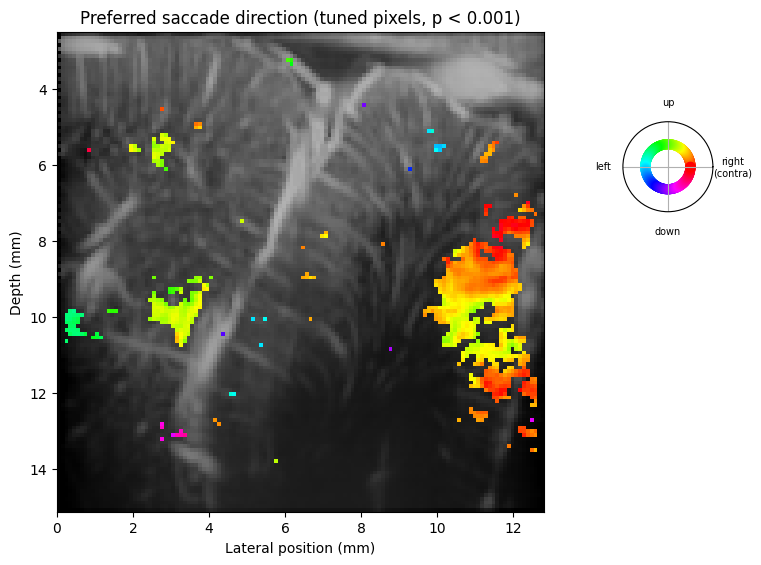

In [11]:
directions = np.unique(S.target_deg)


def direction_tuning(response):
    """Per-pixel direction ANOVA p-value and preferred direction (vector sum) of (trials, ...) responses."""
    by_dir = [response[S.target_deg == d] for d in directions]
    means = np.array([r.mean(axis=0) for r in by_dir])
    with np.errstate(invalid="ignore"):
        _, p = stats.f_oneway(*by_dir, axis=0)
    vector_sum = np.tensordot(np.exp(1j * np.deg2rad(directions)), means - means.mean(axis=0), axes=1)
    return p, np.degrees(np.angle(vector_sum)) % 360


p_anova, preferred = direction_tuning(response_smooth)
tuned = valid & (p_anova < 1e-3)
print(f"{tuned.sum()} pixels tuned to direction at p < 0.001 ({1e-3 * valid.sum():.0f} expected by chance)")


def direction_map(preferred, tuned, angiogram):
    """Color tuned pixels by their preferred direction, on top of the angiogram."""
    hue = np.nan_to_num(preferred) / 360
    rgb = hsv_to_rgb(np.dstack([hue, np.ones_like(hue), np.ones_like(hue)]))
    gray = np.log(np.clip(np.nan_to_num(angiogram), np.nanmin(angiogram[angiogram > 0]), None))
    gray = (gray - gray.min()) / np.ptp(gray) * 0.7
    return np.where(tuned[..., None], rgb, np.dstack([gray] * 3))


fig = plt.figure(figsize=(7.5, 6))
ax = fig.add_axes([0.05, 0.1, 0.65, 0.8])
ax.imshow(direction_map(preferred, tuned, S.angiogram), extent=S.extent)
ax.set_xlabel("Lateral position (mm)")
ax.set_ylabel("Depth (mm)")
ax.set_title("Preferred saccade direction (tuned pixels, p < 0.001)")

# Color wheel legend
wheel = fig.add_axes([0.79, 0.6, 0.15, 0.15], projection="polar")
theta = np.linspace(0, 2 * np.pi, 360)
wheel.scatter(theta, np.ones_like(theta), c=hsv_to_rgb(np.dstack([theta / (2 * np.pi), np.ones(360), np.ones(360)]))[0], s=40)
wheel.set_yticks([])
wheel.set_xticks(np.deg2rad([0, 90, 180, 270]))
wheel.set_xticklabels(["right\n(contra)", "up", "left", "down"], fontsize=7)
plt.show()

Tuned pixels form clusters, and most of them prefer contralateral, upward saccades—consistent with the paper's finding that anterior LIP over-represents contralateral upward movements. Within a cluster, neighboring patches prefer noticeably different directions. Let's look at tuning curves in two small (0.4 × 0.4 mm) regions of the same cluster with different preferences.

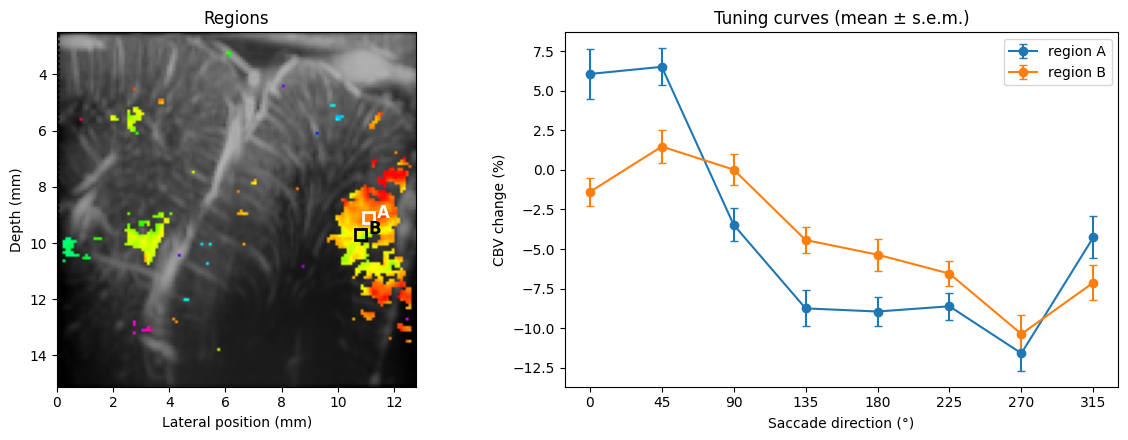

In [12]:
def tuning_curve(center, size=4):
    """Mean response per direction in a size x size pixel region around `center`."""
    iz, ix = center
    region = response[:, iz - size // 2 : iz + size // 2, ix - size // 2 : ix + size // 2]
    per_trial = np.nanmean(region, axis=(1, 2))
    return np.array([per_trial[S.target_deg == d].mean() for d in directions]), np.array(
        [per_trial[S.target_deg == d].std() / np.sqrt(np.sum(S.target_deg == d)) for d in directions]
    )


# Pick the most strongly tuned pixel, then the most strongly tuned pixel within 3 mm
# of it whose preferred direction differs by at least 45 degrees
order = np.argsort(np.where(tuned, p_anova, 1), axis=None)
first = np.unravel_index(order[0], p_anova.shape)
second = next(
    np.unravel_index(i, p_anova.shape)
    for i in order
    if abs((preferred.flat[i] - preferred[first] + 180) % 360 - 180) >= 45
    and np.hypot(*np.subtract(np.unravel_index(i, p_anova.shape), first)) * S.dx_mm <= 3
)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
ax1.imshow(direction_map(preferred, tuned, S.angiogram), extent=S.extent)
for (iz, ix), color, label in [(first, "w", "A"), (second, "k", "B")]:
    x_mm, z_mm = ix * S.dx_mm, S.depth_mm[0] + iz * S.dz_mm
    ax1.add_patch(plt.Rectangle((x_mm - 0.2, z_mm - 0.2), 0.4, 0.4, fill=False, color=color, linewidth=2))
    ax1.text(x_mm + 0.3, z_mm, label, color=color, fontsize=12, fontweight="bold")
    curve, err = tuning_curve((iz, ix))
    ax2.errorbar(directions, curve, err, marker="o", capsize=3, label=f"region {label}")
ax1.set_title("Regions")
ax1.set_xlabel("Lateral position (mm)")
ax1.set_ylabel("Depth (mm)")
ax2.set_xticks(directions)
ax2.set_xlabel("Saccade direction (°)")
ax2.set_ylabel("CBV change (%)")
ax2.set_title("Tuning curves (mean ± s.e.m.)")
ax2.legend()
plt.tight_layout()
plt.show()

Even within a single cluster, regions less than a millimeter apart are tuned differently: region A responds most to rightward and up-right saccades and is suppressed by upward ones, while region B's preference is rotated towards upward saccades. This is the kind of mesoscopic organization that the paper argues fMRI can't resolve. But being able to *see* fine-grained maps and being able to *use* the information they contain are two different things. Let's build a decoder.

# Decoding single trials

Our goal is to predict, from the images of a single trial, which direction the monkey is planning to look. We have ~300 trials and ~15,000 pixels per frame, so we need to reduce the dimensionality before fitting a classifier. Like the paper, we'll use PCA followed by linear discriminant analysis (LDA):

1. **Standardize** each pixel (z-score) using the training trials.
2. **PCA**: keep the principal components that explain 95% of the variance across training trials. With far fewer trials ($n$) than pixels ($p$), it's much cheaper to eigendecompose the $n \times n$ matrix $XX^T$ than the $p \times p$ covariance: if $XX^T = U \Lambda U^T$, the PCA scores of the training trials are $U \Lambda^{1/2}$, and a new trial $x$ projects onto the same components as $x X^T U \Lambda^{-1/2}$.
3. **LDA**: model each class as a Gaussian with its own mean and a shared covariance $\Sigma$, and assign a trial to the class $c$ with the highest score $z^T \Sigma^{-1} \mu_c - \frac{1}{2}\mu_c^T \Sigma^{-1} \mu_c$. We shrink $\Sigma$ towards a multiple of the identity, which keeps the estimate stable with few trials per class.

We evaluate the decoder with 10-fold cross-validation: each trial is predicted by a decoder that never saw it during training.

In [13]:
def make_folds(y, n_folds=10, seed=0):
    """Assign each trial to a fold, spreading every class evenly across folds."""
    rng = np.random.default_rng(seed)
    folds = np.zeros(len(y), dtype=int)
    for c in np.unique(y):
        idx = rng.permutation(np.flatnonzero(y == c))
        folds[idx] = np.arange(len(idx)) % n_folds
    return folds


def pca_scores(X_train, X_test, var_explained=0.95):
    """Project training and test trials onto the principal components of the training trials."""
    mu, sd = X_train.mean(axis=0), X_train.std(axis=0) + 1e-12
    X_train, X_test = (X_train - mu) / sd, (X_test - mu) / sd
    evals, U = np.linalg.eigh(X_train @ X_train.T)  # n_train x n_train
    evals, U = np.clip(evals[::-1], 0, None), U[:, ::-1]
    k = np.searchsorted(np.cumsum(evals) / evals.sum(), var_explained) + 1
    k = min(k, np.sum(evals > 1e-9 * evals[0]))
    s = np.sqrt(evals[:k])
    return U[:, :k] * s, (X_test @ X_train.T) @ U[:, :k] / s


def lda_predict(Z_train, y_train, Z_test, shrinkage=0.5):
    """Linear discriminant analysis with a shrunk, shared covariance matrix."""
    classes = np.unique(y_train)
    means = np.array([Z_train[y_train == c].mean(axis=0) for c in classes])
    resid = Z_train - means[np.searchsorted(classes, y_train)]
    cov = resid.T @ resid / (len(Z_train) - len(classes))
    cov = (1 - shrinkage) * cov + shrinkage * np.trace(cov) / len(cov) * np.eye(len(cov))
    W = np.linalg.solve(cov, means.T)  # Sigma^-1 mu_c for every class
    scores = Z_test @ W - 0.5 * np.sum(means.T * W, axis=0)
    return classes[np.argmax(scores, axis=1)]


def decode(X, y, seeds=(0,), n_folds=10):
    """Cross-validated accuracy (averaged over random fold assignments) and predictions."""
    accuracies, predictions = [], []
    for seed in seeds:
        folds = make_folds(y, n_folds, seed)
        pred = np.empty_like(y)
        for fold in range(n_folds):
            test = folds == fold
            Z_train, Z_test = pca_scores(X[~test], X[test])
            pred[test] = lda_predict(Z_train, y[~test], Z_test)
        accuracies.append(np.mean(pred == y))
        predictions.append(pred)
    return np.mean(accuracies), predictions[0]

We'll decode two things: the full **8-direction** problem (chance = 1/8), and the easier **left vs. right** problem, using only the trials with a horizontal component (chance = 1/2). Our features are the responses of every valid pixel in each frame of the analysis window, concatenated.

In [14]:
y8 = np.searchsorted(directions, S.target_deg)  # direction index, 0..7
y_lr = np.where(right, 1, np.where(left, -1, 0))
lateral = y_lr != 0

X_window = pct[:, window][:, :, valid].reshape(n_trials, -1)

acc8, pred8 = decode(X_window, y8, seeds=(0, 1))
acc_lr, _ = decode(X_window[lateral], y_lr[lateral], seeds=(0, 1))
print(f"8 directions: {acc8:.1%} correct (chance 12.5%)")
print(f"Left vs. right: {acc_lr:.1%} correct (chance 50%)")

8 directions: 40.6% correct (chance 12.5%)
Left vs. right: 83.9% correct (chance 50%)


Is this better than chance? A robust way to check is a permutation test: shuffle the labels, decode again, and repeat many times to see what accuracies we'd get if there was no relationship between images and directions. Since PCA doesn't look at the labels, we can compute it once per fold and only redo the cheap LDA step for each shuffle.

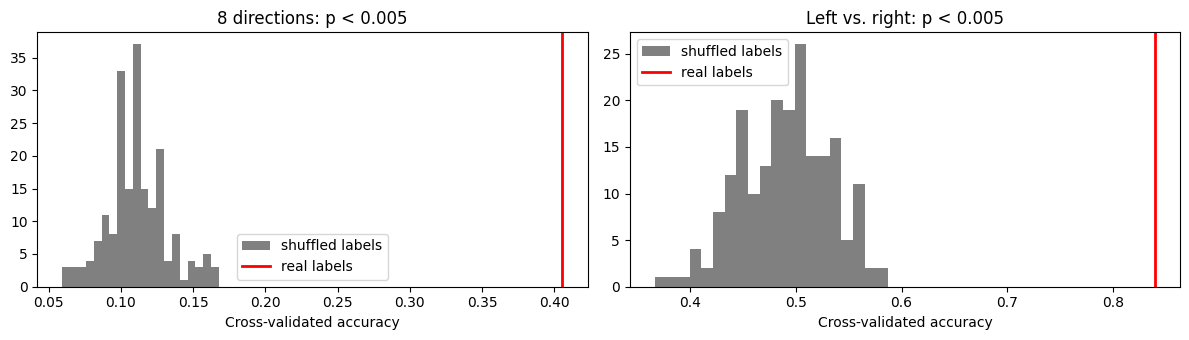

In [15]:
def permutation_null(X, y, n_permutations=200, n_folds=10, seed=0):
    """Accuracies obtained after shuffling the labels, reusing the label-independent PCA."""
    folds = make_folds(y, n_folds, 0)
    cached = [(folds == f, *pca_scores(X[folds != f], X[folds == f])) for f in range(n_folds)]
    rng = np.random.default_rng(seed)
    null = []
    for _ in range(n_permutations):
        y_shuffled = rng.permutation(y)
        pred = np.empty_like(y)
        for test, Z_train, Z_test in cached:
            pred[test] = lda_predict(Z_train, y_shuffled[~test], Z_test)
        null.append(np.mean(pred == y_shuffled))
    return np.array(null)


null8 = permutation_null(X_window, y8)
null_lr = permutation_null(X_window[lateral], y_lr[lateral])

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
for ax, null, acc, title in [(axes[0], null8, acc8, "8 directions"), (axes[1], null_lr, acc_lr, "Left vs. right")]:
    ax.hist(null, bins=20, color="gray", label="shuffled labels")
    ax.axvline(acc, color="r", linewidth=2, label="real labels")
    ax.set_xlabel("Cross-validated accuracy")
    ax.set_title(f"{title}: p < {1 / (len(null) + 1):.3f}" if acc > null.max() else title)
    ax.legend()
plt.tight_layout()
plt.show()

Both are far outside the null distribution. Which mistakes does the 8-direction decoder make?

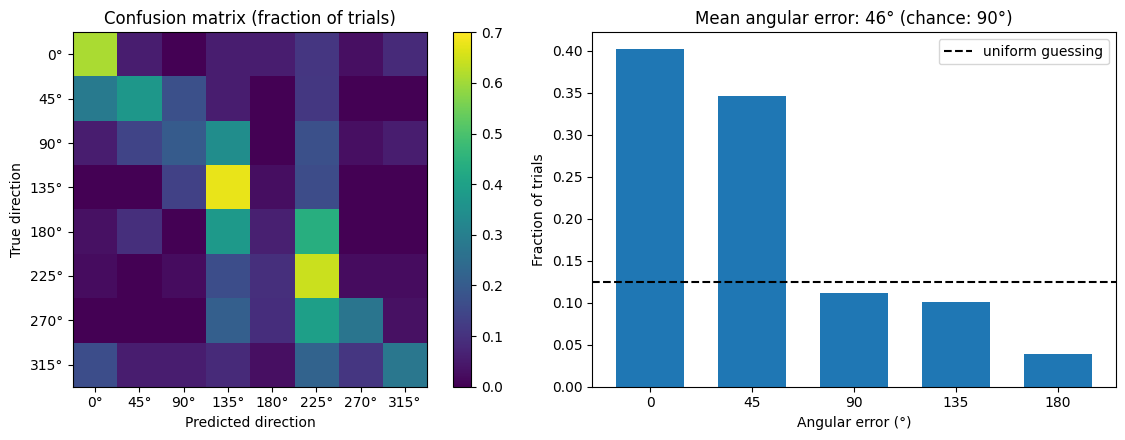

In [16]:
confusion = np.zeros((8, 8))
for true, predicted in zip(y8, pred8):
    confusion[true, predicted] += 1
confusion /= confusion.sum(axis=1, keepdims=True)

angular_error = np.abs((directions[pred8] - directions[y8] + 180) % 360 - 180)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
im = ax1.imshow(confusion, cmap="viridis", vmin=0, vmax=0.7)
ax1.set_xticks(range(8))
ax1.set_xticklabels([f"{d:.0f}°" for d in directions])
ax1.set_yticks(range(8))
ax1.set_yticklabels([f"{d:.0f}°" for d in directions])
ax1.set_xlabel("Predicted direction")
ax1.set_ylabel("True direction")
ax1.set_title("Confusion matrix (fraction of trials)")
plt.colorbar(im, ax=ax1)

errors, counts = np.unique(angular_error, return_counts=True)
ax2.bar(errors, counts / n_trials, width=30)
ax2.axhline(1 / 8, color="k", linestyle="--", label="uniform guessing")
ax2.set_xticks([0, 45, 90, 135, 180])
ax2.set_xlabel("Angular error (°)")
ax2.set_ylabel("Fraction of trials")
ax2.set_title(f"Mean angular error: {angular_error.mean():.0f}° (chance: 90°)")
ax2.legend()
plt.tight_layout()
plt.show()

Most errors are to neighboring directions: the decoder knows roughly where the monkey will look even when it gets the exact target wrong.

The paper reports ~60% 8-direction accuracy for this monkey, using leave-one-out cross-validation and somewhat different preprocessing (detrending, more spatial smoothing). Our simpler pipeline is in the same ballpark, which is all we need for what follows.

## When does the information appear?

Let's decode from each frame separately. Accuracies that fall outside the shaded band are unlikely under chance (95% binomial interval).

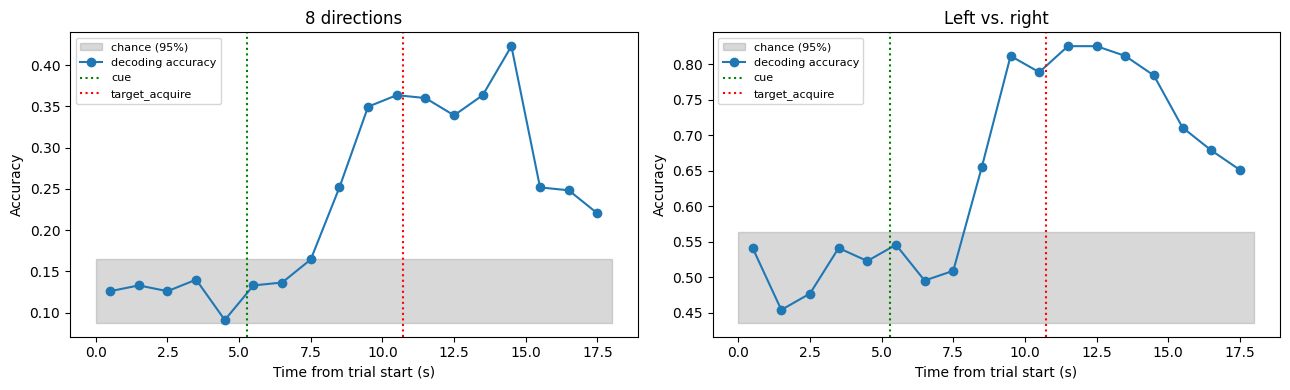

In [17]:
X_frames = pct[:, :, valid]  # (trials, frames, pixels)
acc8_t = [decode(X_frames[:, t], y8)[0] for t in range(n_frames)]
acc_lr_t = [decode(X_frames[lateral, t], y_lr[lateral])[0] for t in range(n_frames)]

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, acc, chance, n, title in [
    (axes[0], acc8_t, 1 / 8, n_trials, "8 directions"),
    (axes[1], acc_lr_t, 1 / 2, lateral.sum(), "Left vs. right"),
]:
    lo, hi = stats.binom.ppf([0.025, 0.975], n, chance) / n
    ax.fill_between([0, n_frames], lo, hi, color="gray", alpha=0.3, label="chance (95%)")
    ax.plot(frame_centers, acc, "o-", label="decoding accuracy")
    for ev, color in [("cue", "g"), ("target_acquire", "r")]:
        ax.axvline(np.median(S.events[ev]), color=color, linestyle=":", label=ev)
    ax.set_xlabel("Time from trial start (s)")
    ax.set_ylabel("Accuracy")
    ax.set_title(title)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

Decoding is at chance until ~3 s after the cue: neurons in LIP start encoding the target as soon as it's flashed, but blood volume takes a few seconds to follow. Information then stays high throughout the memory period and around the saccade. This lag is the price of measuring neural activity through hemodynamics—with fUS just as with fMRI.

# The fMRI question

We now have a decoder that works well on the native fUS data. Let's make the data progressively more fMRI-like, one property at a time.

## Spatial resolution

We'll emulate larger voxels by averaging non-overlapping blocks of pixels. Note that we average the raw Power Doppler and *then* compute the percent change, as an fMRI voxel would sum signal across its volume. Blocks that fall mostly outside the valid image are dropped.

In [18]:
D_valid = np.where(valid, D, np.nan)


def block_average(A, f):
    """Average non-overlapping f x f pixel blocks over the last two axes, ignoring NaNs."""
    Z, X = (A.shape[-2] // f) * f, (A.shape[-1] // f) * f
    blocks = A[..., :Z, :X].reshape(*A.shape[:-2], Z // f, f, X // f, f)
    n_valid = np.isfinite(blocks).sum(axis=(-3, -1))
    total = np.nansum(blocks, axis=(-3, -1))
    # Keep blocks that are mostly inside the valid image
    return np.where(n_valid > f * f / 2, total / np.maximum(n_valid, 1), np.nan)


def voxel_pct(f):
    """Percent change images (trials, frames, nz // f, nx // f) for voxels of f x f pixels."""
    Db = block_average(D_valid, f)
    base = Db[:, baseline].mean(axis=1, keepdims=True)
    return (Db - base) / base.mean(axis=0, keepdims=True) * 100


def voxel_responses(f):
    """Percent change of every valid voxel in every frame: (trials, frames, voxels)."""
    V = voxel_pct(f)
    return V[..., np.isfinite(V).all(axis=(0, 1))]


block_sizes = [1, 2, 3, 5, 10, 15, 20]  # in pixels of ~0.1 mm
voxel_mm = np.array(block_sizes) * S.dx_mm

Here's what the angiogram and the direction map look like at increasingly coarse resolutions:

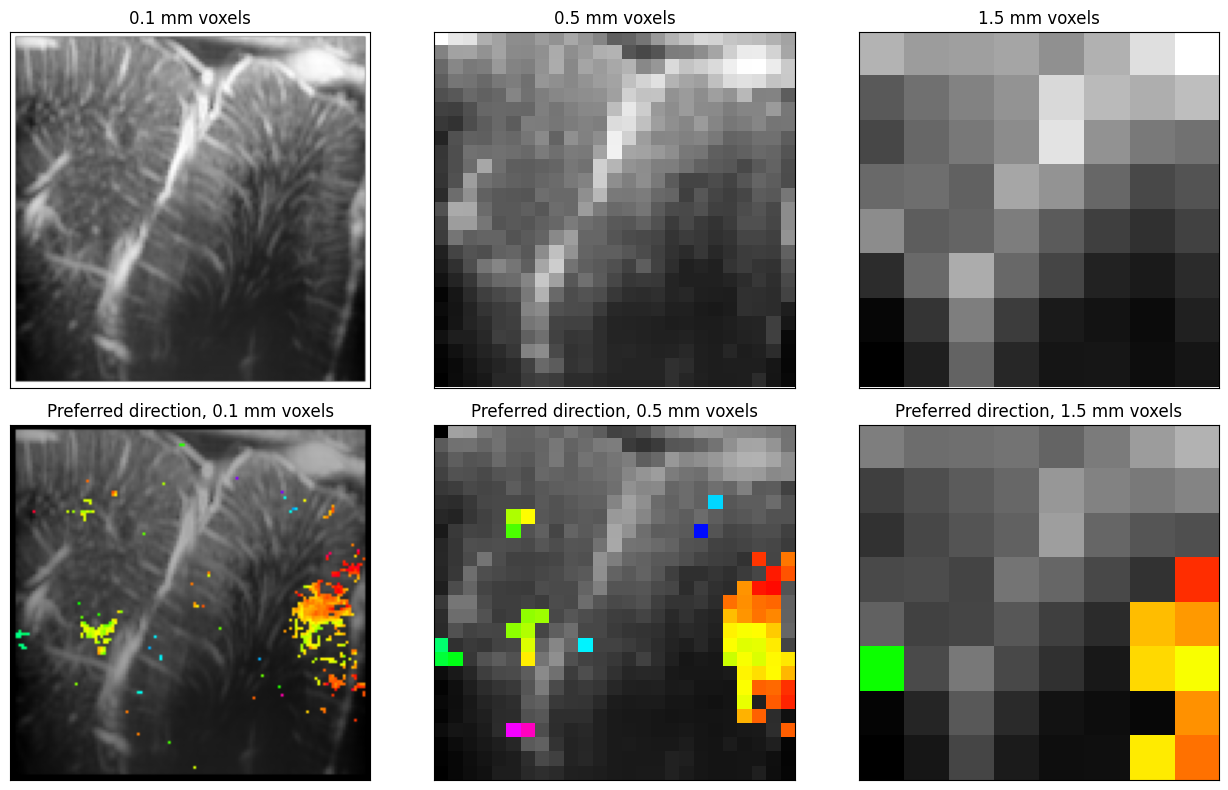

In [19]:
fig, axes = plt.subplots(2, 3, figsize=(13, 8))
for col, f in enumerate([1, 5, 15]):
    angio = block_average(np.where(valid, S.angiogram, np.nan), f)
    axes[0, col].imshow(np.log(angio), cmap="gray", extent=S.extent)
    axes[0, col].set_title(f"{f * S.dx_mm:.1f} mm voxels")

    p, pref = direction_tuning(voxel_pct(f)[:, window].mean(axis=1))
    good = np.isfinite(p) & (p < 1e-3)
    axes[1, col].imshow(direction_map(pref, good, angio), extent=S.extent)
    axes[1, col].set_title(f"Preferred direction, {f * S.dx_mm:.1f} mm voxels")
for ax in axes.ravel():
    ax.set_xticks([])
    ax.set_yticks([])
plt.tight_layout()
plt.show()

At 1.5 mm, the patches have merged into a handful of voxels with mostly the same preference. Visually, the mesoscopic organization is gone. What about decoding?

0.1 mm voxels: 8 directions 40.6%, left/right 83.9%


0.2 mm voxels: 8 directions 44.2%, left/right 85.6%


0.3 mm voxels: 8 directions 49.5%, left/right 86.2%


0.5 mm voxels: 8 directions 48.1%, left/right 87.2%


1.0 mm voxels: 8 directions 45.3%, left/right 87.4%


1.5 mm voxels: 8 directions 37.1%, left/right 81.2%


2.0 mm voxels: 8 directions 38.8%, left/right 80.0%


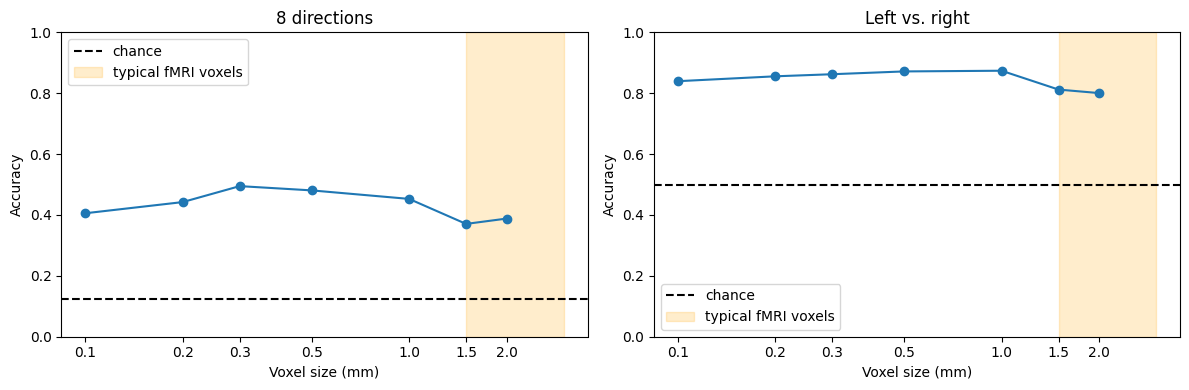

In [20]:
acc8_res, acc_lr_res = [], []
for f in block_sizes:
    Xv = voxel_responses(f)[:, window].reshape(n_trials, -1)
    acc8_res.append(decode(Xv, y8, seeds=(0, 1))[0])
    acc_lr_res.append(decode(Xv[lateral], y_lr[lateral], seeds=(0, 1))[0])
    print(f"{f * S.dx_mm:.1f} mm voxels: 8 directions {acc8_res[-1]:.1%}, left/right {acc_lr_res[-1]:.1%}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, acc, chance, title in [(axes[0], acc8_res, 1 / 8, "8 directions"), (axes[1], acc_lr_res, 1 / 2, "Left vs. right")]:
    ax.plot(voxel_mm, acc, "o-")
    ax.axhline(chance, color="k", linestyle="--", label="chance")
    ax.axvspan(1.5, 3.0, color="orange", alpha=0.2, label="typical fMRI voxels")
    ax.set_xscale("log")
    ax.minorticks_off()
    ax.set_xticks(voxel_mm)
    ax.set_xticklabels([f"{v:.1f}" for v in voxel_mm])
    ax.set_xlabel("Voxel size (mm)")
    ax.set_ylabel("Accuracy")
    ax.set_ylim(0, 1)
    ax.set_title(title)
    ax.legend()
plt.tight_layout()
plt.show()

This is perhaps surprising. Mild averaging (0.2-1 mm) actually *helps*: it averages out noise faster than it destroys signal. At 1.5-2 mm, where the direction map has visibly collapsed, 8-direction accuracy is roughly back where it started at full resolution—about 10 points below its best—and left vs. right is barely affected. The coarse voxels still carry most of the information, mixed together in ways a linear decoder can untangle.

## Temporal resolution

fMRI volumes are typically acquired every 1-3 s (the repetition time, TR). Let's bin our 1 s frames into longer bins and decode from each bin.

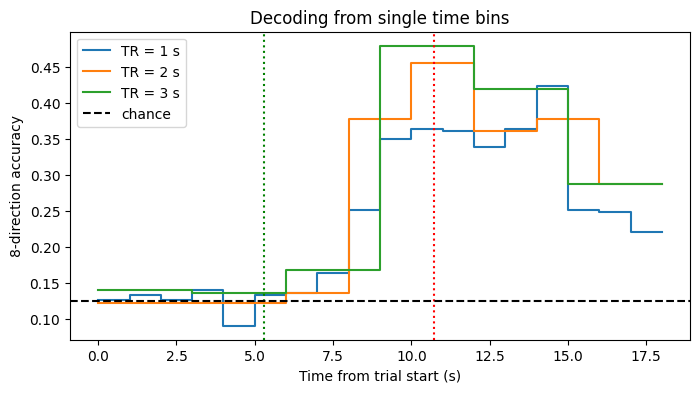

In [21]:
fig, ax = plt.subplots(figsize=(8, 4))
for TR in [1, 2, 3]:
    n_bins = n_frames // TR
    X_binned = X_frames[:, : n_bins * TR].reshape(n_trials, n_bins, TR, -1).mean(axis=2)
    acc = [decode(X_binned[:, b], y8)[0] for b in range(n_bins)]
    ax.step(np.arange(n_bins + 1) * TR, acc + acc[-1:], where="post", label=f"TR = {TR} s")
for ev, color in [("cue", "g"), ("target_acquire", "r")]:
    ax.axvline(np.median(S.events[ev]), color=color, linestyle=":")
ax.axhline(1 / 8, color="k", linestyle="--", label="chance")
ax.set_xlabel("Time from trial start (s)")
ax.set_ylabel("8-direction accuracy")
ax.set_title("Decoding from single time bins")
ax.legend()
plt.show()

Longer bins don't hurt: the memory period lasts ~5 s and the hemodynamic response is slow anyway, so averaging frames mostly averages out noise. What longer TRs cost is *timing*: with 3 s bins, we can no longer tell precisely when the information appears. For decoding a sustained plan, sampling speed is not the bottleneck.

## Sensitivity

Block-averaging doesn't just blur the image: it also averages out noise. To see how these two effects trade off, let's measure the **contrast-to-noise ratio** (CNR) of the direction signal. For each voxel, we take the difference between its mean responses to contralateral and ipsilateral saccades, and divide it by its trial-to-trial noise (a single-trial $d'$).

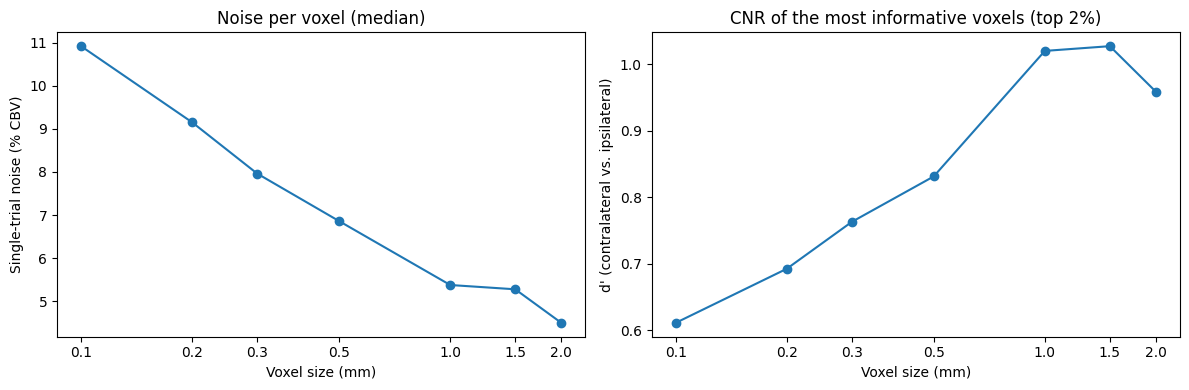

In [22]:
noise_by_size, dprime_by_size = [], []
for f in block_sizes:
    V = voxel_responses(f)[:, window].mean(axis=1)  # (trials, voxels), averaged over the window
    contrast = V[right].mean(axis=0) - V[left].mean(axis=0)
    noise = np.sqrt((V[right].var(axis=0) + V[left].var(axis=0)) / 2)
    dprime = np.sort(np.abs(contrast) / noise)
    noise_by_size.append(np.median(noise))
    dprime_by_size.append(dprime[-max(1, len(dprime) // 50) :].mean())  # best 2% of voxels

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(voxel_mm, noise_by_size, "o-")
ax1.set_ylabel("Single-trial noise (% CBV)")
ax1.set_title("Noise per voxel (median)")
ax2.plot(voxel_mm, dprime_by_size, "o-")
ax2.set_ylabel("d' (contralateral vs. ipsilateral)")
ax2.set_title("CNR of the most informative voxels (top 2%)")
for ax in (ax1, ax2):
    ax.set_xscale("log")
    ax.minorticks_off()
    ax.set_xticks(voxel_mm)
    ax.set_xticklabels([f"{v:.1f}" for v in voxel_mm])
    ax.set_xlabel("Voxel size (mm)")
plt.tight_layout()
plt.show()

As voxels grow, the noise drops quickly while the direction signal is only partly diluted, so the CNR of the best voxels goes *up*. That's why coarse voxels decode so well here. fMRI doesn't get this for free: its noise at a given voxel size is set by the physics of MRI, and its signal is smaller. The paper quotes BOLD changes of ~0.4-2% for saccade tasks, versus ~10-30% CBV changes with fUS.

So how much CNR can the decoder afford to lose? We can emulate a less sensitive modality by adding Gaussian noise to every voxel and frame, scaled so that the total noise is $k$ times the measured fUS noise (i.e. the added noise has standard deviation $\sqrt{k^2-1}$ times the original). We'll average over two independent noise draws, and decode across a grid of voxel sizes and noise factors.

In [23]:
rng = np.random.default_rng(0)
noise_factors = [1, 1.5, 2, 3, 5]
grid_sizes = [1, 3, 5, 10, 15, 20]


def add_noise(V, factor):
    """Add Gaussian noise so that each voxel's trial-to-trial noise is `factor` times larger."""
    if factor == 1:
        return V
    sigma = np.concatenate([V[y8 == c] - V[y8 == c].mean(axis=0) for c in range(8)]).std(axis=0)
    return V + rng.normal(size=V.shape) * sigma * np.sqrt(factor**2 - 1)


grid8 = np.zeros((len(noise_factors), len(grid_sizes)))
grid_lr = np.zeros_like(grid8)
for j, f in enumerate(grid_sizes):
    V = voxel_responses(f)[:, window]
    for i, k in enumerate(noise_factors):
        for seed in (0, 1):
            Xv = add_noise(V, k).reshape(n_trials, -1)
            grid8[i, j] += decode(Xv, y8, seeds=(seed,))[0] / 2
            grid_lr[i, j] += decode(Xv[lateral], y_lr[lateral], seeds=(seed,))[0] / 2

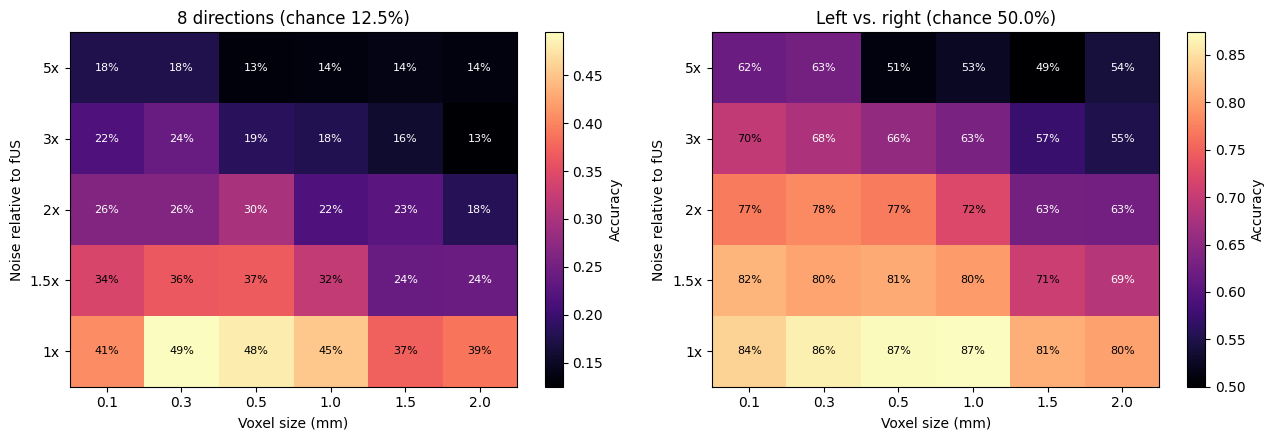

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, grid, chance, title in [(axes[0], grid8, 1 / 8, "8 directions"), (axes[1], grid_lr, 1 / 2, "Left vs. right")]:
    im = ax.imshow(grid, cmap="magma", vmin=chance, vmax=grid.max(), origin="lower", aspect="auto")
    for i in range(len(noise_factors)):
        for j in range(len(grid_sizes)):
            ax.text(j, i, f"{grid[i, j]:.0%}", ha="center", va="center", fontsize=8,
                    color="w" if grid[i, j] < (chance + grid.max()) / 2 else "k")
    ax.set_xticks(range(len(grid_sizes)))
    ax.set_xticklabels([f"{f * S.dx_mm:.1f}" for f in grid_sizes])
    ax.set_yticks(range(len(noise_factors)))
    ax.set_yticklabels([f"{k}x" for k in noise_factors])
    ax.set_xlabel("Voxel size (mm)")
    ax.set_ylabel("Noise relative to fUS")
    ax.set_title(f"{title} (chance {chance:.1%})")
    plt.colorbar(im, ax=ax, label="Accuracy")
plt.tight_layout()
plt.show()

Reading the grid along each axis tells the story:

* **Horizontally** (bigger voxels, same noise), accuracy changes slowly.
* **Vertically** (same voxels, more noise), accuracy collapses: doubling the noise costs more than going from 0.1 mm to 2 mm voxels, and by 3-5x the 8-direction decoder approaches chance.

Here's the column for fMRI-like 1.5 mm voxels:

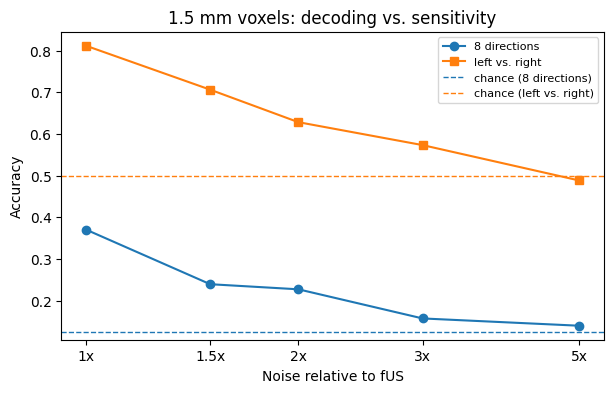

In [25]:
j15 = grid_sizes.index(15)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(noise_factors, grid8[:, j15], "o-", label="8 directions")
ax.plot(noise_factors, grid_lr[:, j15], "s-", label="left vs. right")
ax.axhline(1 / 8, color="C0", linestyle="--", linewidth=1, label="chance (8 directions)")
ax.axhline(1 / 2, color="C1", linestyle="--", linewidth=1, label="chance (left vs. right)")
ax.set_xscale("log")
ax.minorticks_off()
ax.set_xticks(noise_factors)
ax.set_xticklabels([f"{k}x" for k in noise_factors])
ax.set_xlabel("Noise relative to fUS")
ax.set_ylabel("Accuracy")
ax.set_title("1.5 mm voxels: decoding vs. sensitivity")
ax.legend(fontsize=8)
plt.show()

## Where would fMRI sit?

Placing fMRI precisely on this axis would require fMRI data from the same task: what matters is the size of the *direction-specific* part of the BOLD response relative to fMRI noise at that voxel size, and neither number is well established for monkey LIP. What we can say is that the decoder's margin is thin. Losing a factor of 2 in CNR costs more than making voxels 20 times larger, and a factor of 3-5 brings 8-direction decoding close to chance. BOLD changes are roughly an order of magnitude smaller than the CBV changes measured with fUS, only partly offset by fMRI's noise also being smaller in percent terms, so it is plausible that fMRI sits in that regime.

In this dataset, then, **fUS's edge for decoding seems to come more from its sensitivity than from its resolution.** This complements the paper rather than contradicting it: resolving the *maps*—where each direction is represented—genuinely requires small voxels, as we saw above. Decoding asks a different question, and linear decoders are good at pulling information out of mixtures.

# Caveats

This is a deliberately simple analysis, and several of its simplifications favor fMRI:

* **A single 2D slice.** Our fUS voxels are 400 μm thick, and we only averaged within the plane. A 1.5 mm fMRI voxel also averages across ~4 such slices, mixing in more differently-tuned tissue. On the other hand, fMRI covers the whole brain, and a decoder could pool information from many regions.
* **CBV vs. BOLD.** BOLD signals are dominated by draining veins downstream of the active tissue, which blurs them beyond the nominal voxel size. Block-averaging Power Doppler doesn't capture that.
* **Idealized noise.** We added independent Gaussian noise. Real fMRI noise is dominated by physiological fluctuations that are correlated across voxels and time, which is harder on a decoder than independent noise.
* **One session.** All numbers come from one session of one monkey. Session 39 (monkey L) decodes less well, for instance; the paper also shows that decoders can be trained on one day and tested months later.

# Exercises

* Repeat the analysis with another session (see `sessions` above). For session 39, you'll need to estimate and subtract the constant offset first (hint: where does the line in the "units" plot cross zero standard deviation?).
* Restrict the decoder to the frames before the saccade (accounting for the hemodynamic lag). How much of the information is about the *plan* rather than the movement?
* Replace the independent noise with noise that is correlated across voxels (e.g. a shared global fluctuation). How does that change the picture?

# References

* [Griggs et al. 2025](https://www.ncbi.nlm.nih.gov/pmc/articles/PMC12488887/). Functional ultrasound neuroimaging reveals mesoscopic organization of saccades in the lateral intraparietal area. *Nature Communications*. [Dataset](https://data.caltech.edu/records/p5jan-02r60).
* [Norman et al. 2021](https://pubmed.ncbi.nlm.nih.gov/33756104/). Single-trial decoding of movement intentions using functional ultrasound neuroimaging. *Neuron*.
* [Macé et al. 2011](https://www.nature.com/articles/nmeth.1641). Functional ultrasound imaging of the brain. *Nature Methods*.